In [1]:
import os
import re
import pickle
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import json
import glob
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)
pd.set_option('display.max_colwidth', None)

# Dataset Choice

In [2]:
json_dir = '../results/2024_flight/'
save_db = 'travels_2024.pkl'

# Retrieve Results

In [3]:
flattened_data = []
json_files = glob.glob(os.path.join(json_dir, '*.json'))
for json_file in json_files: 
    with open(json_file, 'r') as f:
        try:
            data = json.load(f)
            for author_data in data:
                author = author_data['author']
                for flight in author_data['flights']:
                    record = {
                        'author': author,
                        'commit_a': flight['commits'][0],
                        'commit_b': flight['commits'][1],
                        'timestamp_a': flight['timestamps'][0],
                        'timestamp_b': flight['timestamps'][1],
                        'timezones': flight['timezones'],
                    }
                    flattened_data.append(record)
        except Exception as e:
            print(f"Error processing file {json_file}: {e}")
df = pd.DataFrame(flattened_data)

Retrieving time: **4min**

In [4]:
df['year'] = pd.to_datetime(df['timestamp_a']).dt.year
df.head()

,author,commit_a,commit_b,timestamp_a,timestamp_b,timezones,year
0,53089bfb83b74a209fd03d966b806b826212f24e619c2df92ec2e1c6d877d54b,fbed3efb7adc68f6adde7daef27786404119c2ed,03c9e124b50af7d42feb09aafeb3f93a70a6430b,2019-11-21T20:08:23Z,2019-11-21T20:08:53Z,"[-300, 0]",2019
1,53089bfb83b74a209fd03d966b806b826212f24e619c2df92ec2e1c6d877d54b,a95c44976970d16c3a85b50be30e8a5c3274b7cf,4da87cec7356ba7742eed3dfcaef4c5992263094,2019-11-21T20:16:48Z,2019-11-21T20:17:42Z,"[-300, 0]",2019
2,53089bfb83b74a209fd03d966b806b826212f24e619c2df92ec2e1c6d877d54b,1b29750dcc90e351726a657d326ee72e7f7fdb3e,ef1db37b4bcb7fe94fdaedcf7f600f82f1784779,2019-11-21T20:23:33Z,2019-11-21T20:24:45Z,"[-300, 0]",2019
3,53089bfb83b74a209fd03d966b806b826212f24e619c2df92ec2e1c6d877d54b,2d105a9463e3ca1d06be81276c444f9495636a58,1c1d8b2a99926b7677102a56106d7b163c5eae80,2019-11-21T20:29:56Z,2019-11-21T20:31:36Z,"[-300, 0]",2019
4,53089bfb83b74a209fd03d966b806b826212f24e619c2df92ec2e1c6d877d54b,b6cd942cdcd8ae9e4cc6ee0b7540276227a1550a,fe736d1347e18d751870c65bb14013b53ee90479,2019-11-21T20:38:28Z,2019-11-21T20:39:37Z,"[-300, 0]",2019


## Saving and Loading Results

In [5]:
with open(save_db, 'wb') as f:
    pickle.dump(df, f)

Saving time: **1min**

In [6]:
with open(save_db, 'rb') as f:
    df = pickle.load(f)

Loading time: **2min**

In [7]:
df.head()

,author,commit_a,commit_b,timestamp_a,timestamp_b,timezones,year
0,53089bfb83b74a209fd03d966b806b826212f24e619c2df92ec2e1c6d877d54b,fbed3efb7adc68f6adde7daef27786404119c2ed,03c9e124b50af7d42feb09aafeb3f93a70a6430b,2019-11-21T20:08:23Z,2019-11-21T20:08:53Z,"[-300, 0]",2019
1,53089bfb83b74a209fd03d966b806b826212f24e619c2df92ec2e1c6d877d54b,a95c44976970d16c3a85b50be30e8a5c3274b7cf,4da87cec7356ba7742eed3dfcaef4c5992263094,2019-11-21T20:16:48Z,2019-11-21T20:17:42Z,"[-300, 0]",2019
2,53089bfb83b74a209fd03d966b806b826212f24e619c2df92ec2e1c6d877d54b,1b29750dcc90e351726a657d326ee72e7f7fdb3e,ef1db37b4bcb7fe94fdaedcf7f600f82f1784779,2019-11-21T20:23:33Z,2019-11-21T20:24:45Z,"[-300, 0]",2019
3,53089bfb83b74a209fd03d966b806b826212f24e619c2df92ec2e1c6d877d54b,2d105a9463e3ca1d06be81276c444f9495636a58,1c1d8b2a99926b7677102a56106d7b163c5eae80,2019-11-21T20:29:56Z,2019-11-21T20:31:36Z,"[-300, 0]",2019
4,53089bfb83b74a209fd03d966b806b826212f24e619c2df92ec2e1c6d877d54b,b6cd942cdcd8ae9e4cc6ee0b7540276227a1550a,fe736d1347e18d751870c65bb14013b53ee90479,2019-11-21T20:38:28Z,2019-11-21T20:39:37Z,"[-300, 0]",2019


# Analysis

### Basic Stats

In [8]:
author_stats = pd.DataFrame({
    'total_flights': df.groupby('author').size(),
    'unique_patterns': df.groupby('author')['timezones'].apply(lambda x: len(set(tuple(tz) for tz in x))),
})

**2min**

In [9]:
author_stats.head(2)

,total_flights,unique_patterns
author,,
000004ce1e8b2d27a17eff682ee038222519d0139e2e870128c713ef46ab1f20,1,1
000014b10fb13559dfd44bc447b49334ffbbf793f8859e478bd369d384cdc013,5,2


In [10]:
max_stats = {
    'total_flights': author_stats['total_flights'].idxmax(),
    'unique_patterns': author_stats['unique_patterns'].idxmax(),
}

max_authors = pd.DataFrame({
    'statistic': max_stats.keys(),
    'author': max_stats.values(),
    'value': [author_stats.loc[max_stats[stat], stat] for stat in max_stats.keys()]
})
# what date for unique pattern ? Old ?
max_authors

,statistic,author,value
0,total_flights,af1aa96f31a617f882a08a20d921fd165a7c0c3957cdbc566ea1541cefde0545,1434271
1,unique_patterns,d2833f622cce50d1194cabd68ab1f50be3f55e0d07acf37e525daae9ee13fa39,943


### Timezone Pattern

In [11]:
timezone_patterns = df.groupby('author')['timezones'].apply(
    lambda x: [tuple(w) for w in x]
)
common_patterns = pd.Series([p for patterns in timezone_patterns for p in patterns]).value_counts()

### Graphic

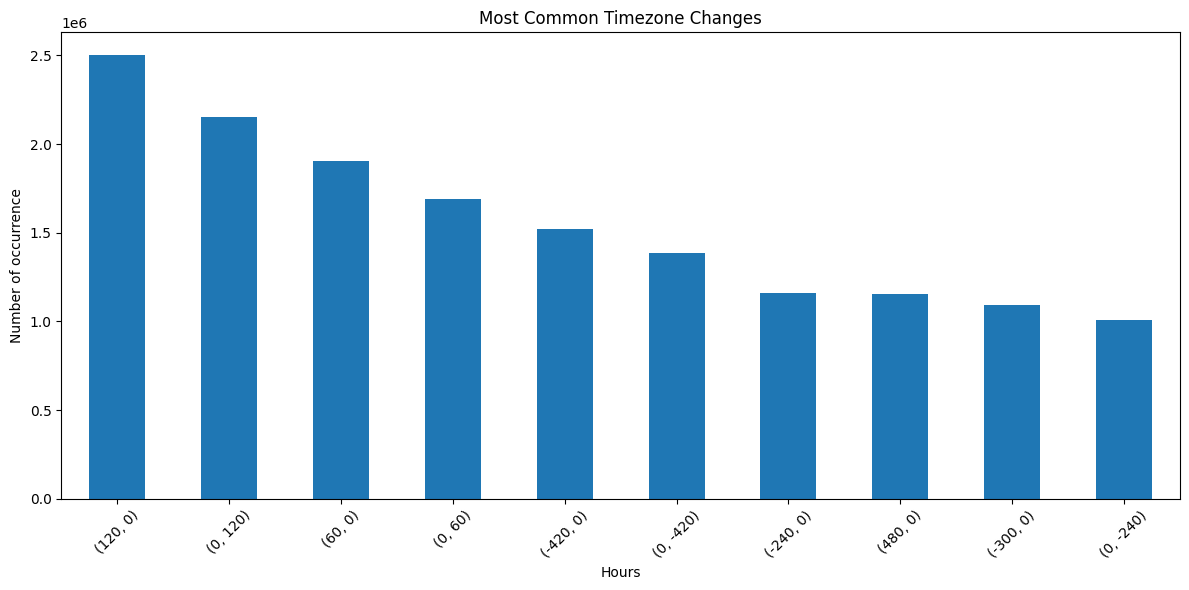

In [12]:
""" plt.figure(figsize=(10,6))
sns.histplot(data=[d for durations in window_durations for d in durations if isinstance(durations, list)])
plt.title('Window Durations Distribution')
plt.xlabel('Hours') """

plt.figure(figsize=(12,6))
common_patterns.head(10).plot(kind='bar')
plt.title('Most Common Timezone Changes')
plt.ylabel('Number of occurrence')
plt.xlabel('Hours') 
plt.xticks(rotation=45)
plt.tight_layout()

## Without UTC

In [13]:
df_without_utc = df.loc[df['timezones'].apply(lambda x: 0 not in x)]

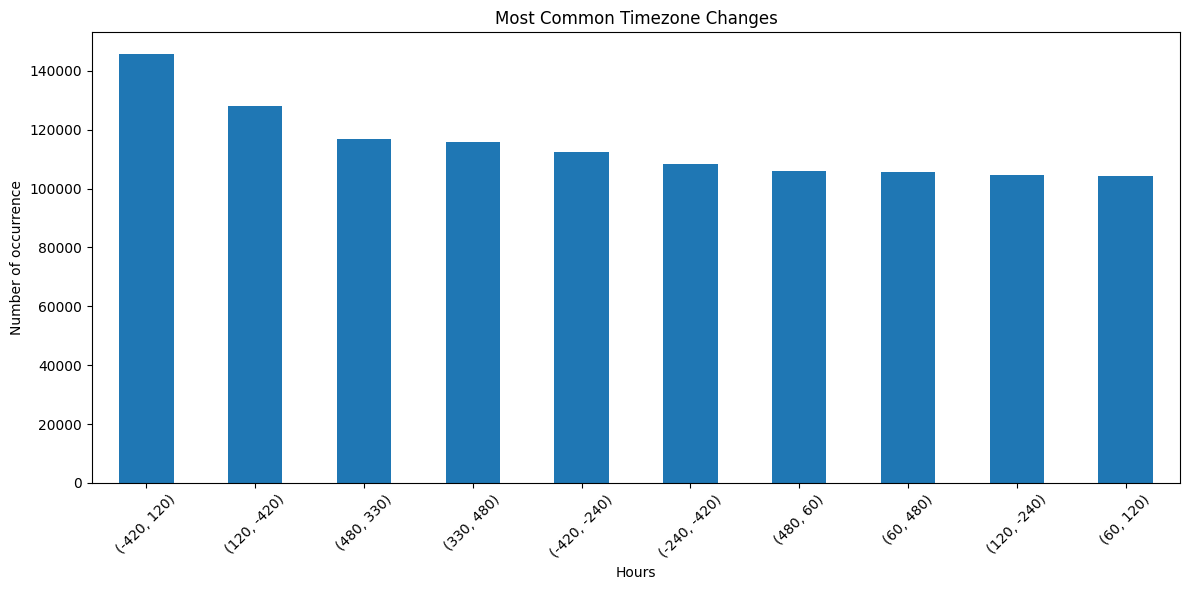

In [14]:
timezone_patterns_without_UTC = df_without_utc.groupby('author')['timezones'].apply(
    lambda x: [tuple(w) for w in x]
)
common_patterns_without_UTC = pd.Series([p for patterns_without_UTC in timezone_patterns_without_UTC for p in patterns_without_UTC]).value_counts()
plt.figure(figsize=(12,6))
common_patterns_without_UTC.head(10).plot(kind='bar')
plt.title('Most Common Timezone Changes')
plt.ylabel('Number of occurrence')
plt.xlabel('Hours') 
plt.xticks(rotation=45)
plt.tight_layout()

## Timezones that are not %60

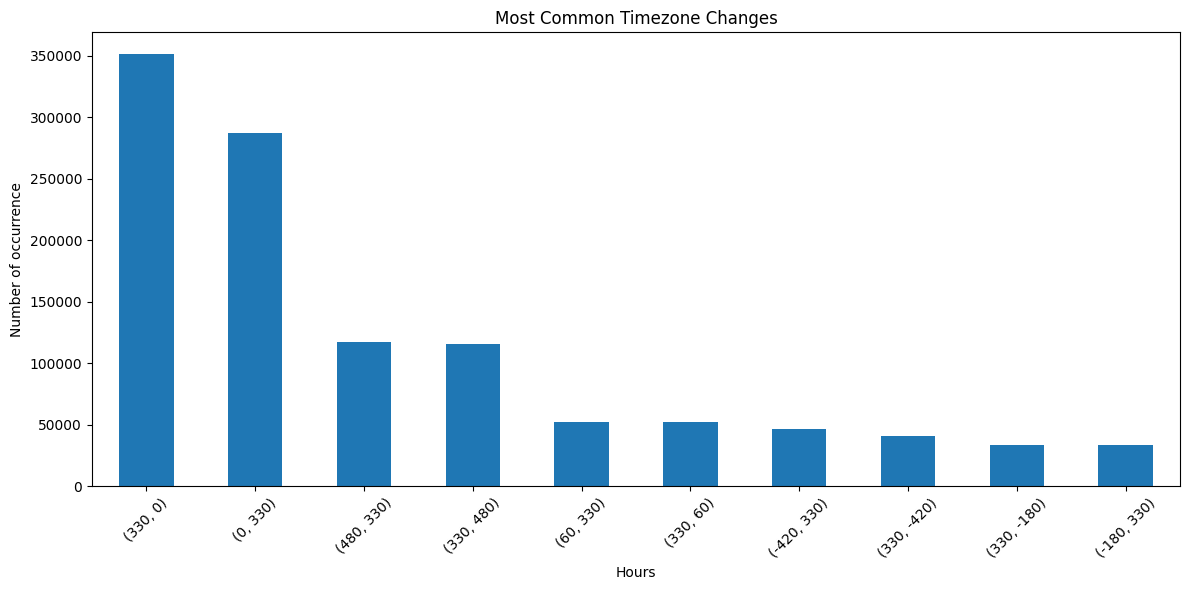

In [15]:
df_only_partial = df.loc[df['timezones'].apply(lambda x: any(element % 60 != 0 for element in x))]
timezone_patterns_only_partial = df_only_partial.groupby('author')['timezones'].apply(
    lambda x: [tuple(w) for w in x]
)
common_patterns_only_partial = pd.Series([p for patterns_only_partial in timezone_patterns_only_partial for p in patterns_only_partial]).value_counts()
plt.figure(figsize=(12,6))
common_patterns_only_partial.head(10).plot(kind='bar')
plt.title('Most Common Timezone Changes')
plt.ylabel('Number of occurrence')
plt.xlabel('Hours') 
plt.xticks(rotation=45)
plt.tight_layout()

## Patterns without UTC and with non 60min timezone

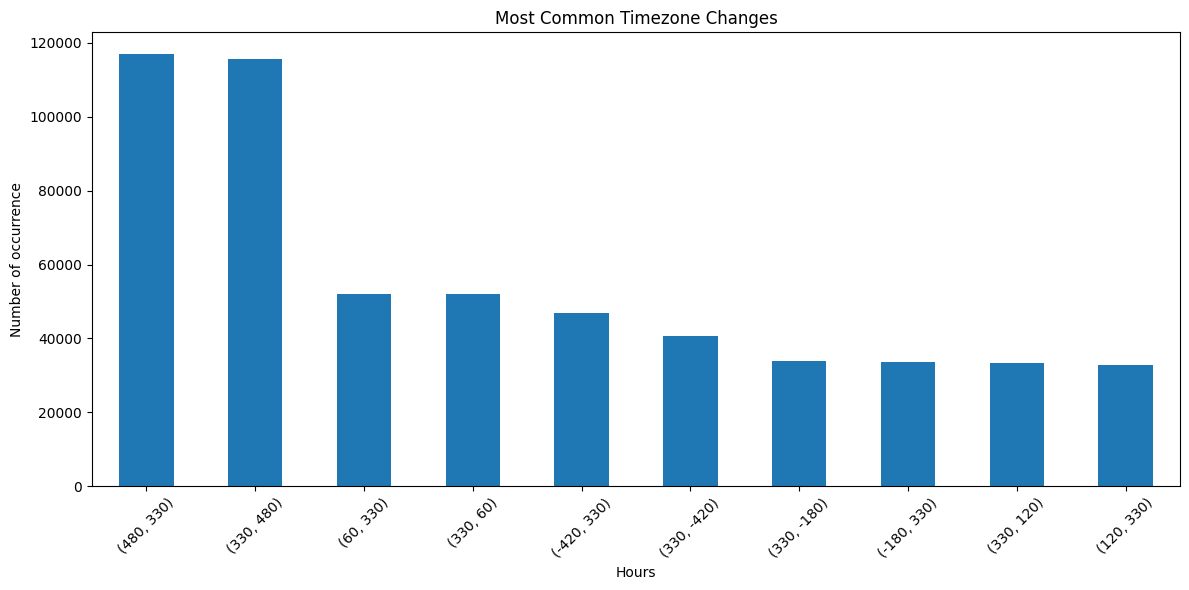

In [16]:
df_almost_exotic = df_without_utc.loc[df_without_utc['timezones'].apply(lambda x: any(element % 60 != 0 for element in x))]
timezone_patterns_almost_exotic = df_almost_exotic.groupby('author')['timezones'].apply(
    lambda x: [tuple(w) for w in x]
)
common_patterns_almost_exotic = pd.Series([p for patterns_almost_exotic in timezone_patterns_almost_exotic for p in patterns_almost_exotic]).value_counts()
plt.figure(figsize=(12,6))
common_patterns_almost_exotic.head(10).plot(kind='bar')
plt.title('Most Common Timezone Changes')
plt.ylabel('Number of occurrence')
plt.xlabel('Hours') 
plt.xticks(rotation=45)
plt.tight_layout()

## Patterns without UTC and with non 30min timezone

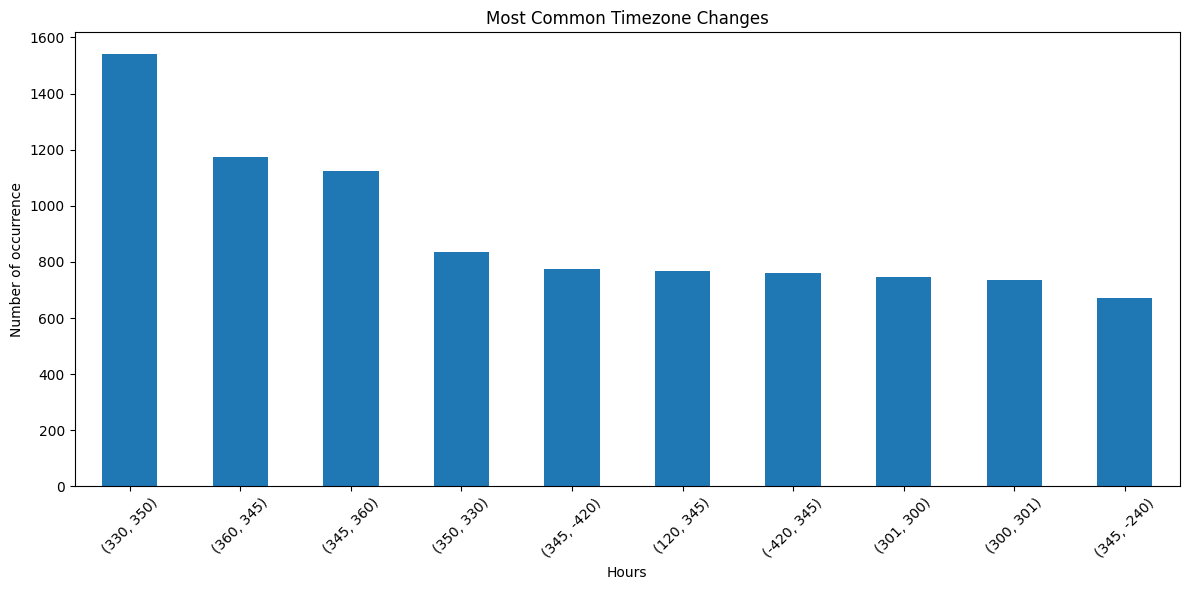

In [17]:
df_exotic = df_without_utc.loc[df_without_utc['timezones'].apply(lambda x: any(element % 30 != 0 for element in x))]
timezone_patterns_exotic = df_exotic.groupby('author')['timezones'].apply(
    lambda x: [tuple(w) for w in x]
)
common_patterns_exotic = pd.Series([p for patterns_exotic in timezone_patterns_exotic for p in patterns_exotic]).value_counts()
plt.figure(figsize=(12,6))
common_patterns_exotic.head(10).plot(kind='bar')
plt.title('Most Common Timezone Changes')
plt.ylabel('Number of occurrence')
plt.xlabel('Hours') 
plt.xticks(rotation=45)
plt.tight_layout()

## Amount of patterns through years
It goes from 1970 to 2078, we display only those between 1995 and 2024.

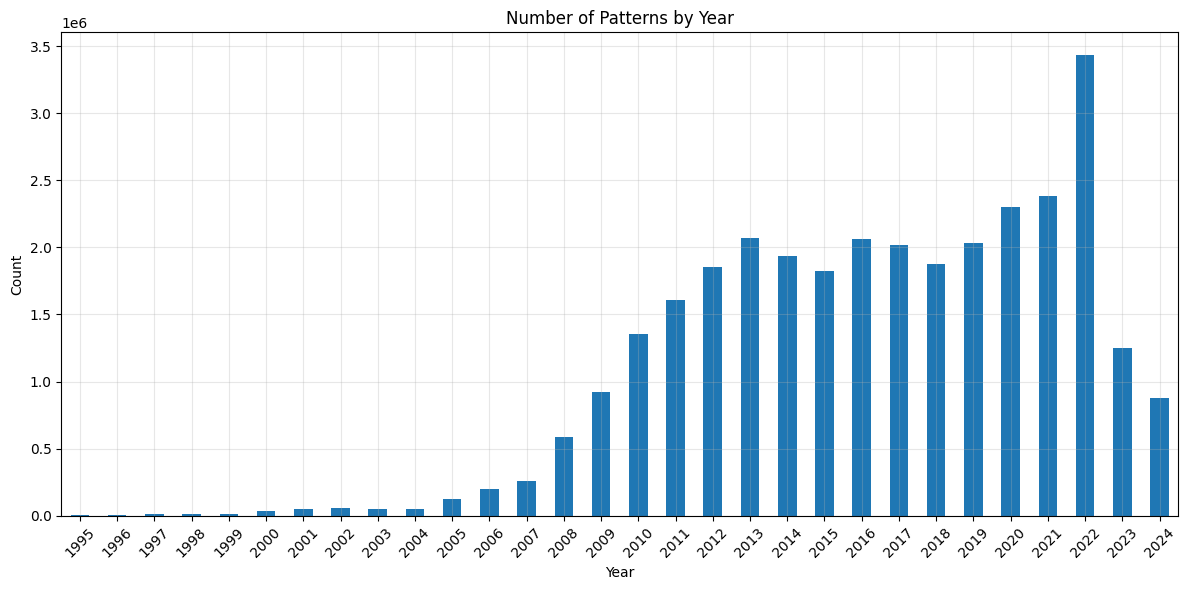

In [19]:
pattern_by_year = df['year'][(df['year'] >= 1995) & (df['year'] <= 2024)].value_counts().sort_index()
#pattern_by_year = df['year'].value_counts().sort_index()
plt.figure(figsize=(12, 6))
pattern_by_year.plot(kind='bar')
plt.title('Number of Patterns by Year')
plt.xlabel('Year')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Jia Tan

In [ ]:
commit_to_find = ['6a86e81cab202d0a812a7b2e9efacaf70c58ba38', '84963318952064a93bfc52edd6b0ef70593384ee', '827ac5b4821491fd3afe0d0e1ddac326253aeb66']
matching_rows = df[df['commits'].apply(lambda x: x[0] in commit_to_find or x[1] in commit_to_find)]

matching_rows